# Experiment 9 — CNN for Bird Species Classification

**Aim:** Train a Convolutional Neural Network to classify bird species from the CUB-200-2011 image dataset.

**Libraries:** Python, TensorFlow/Keras, NumPy, pandas, Matplotlib, and scikit-learn.

**Theory:** Convolution layers learn local image features with shared filters; pooling reduces spatial resolution. Transfer learning reuses a pretrained CNN feature extractor, then adapts it to the bird classes. Training-only augmentation can improve robustness.

**Dataset:** CUB-200-2011, published by Caltech. The notebook downloads the official archive only if missing and extracts a small five-species subset. The archive is large and is not committed to this repository. Check the source's current use and redistribution terms and confirm dataset uniqueness with the instructor.

## Procedure / Implementation
Prepare the selected image subset, make stratified train/validation/test splits, fine-tune a pretrained CNN, and record actual held-out metrics and figures.

## 1. Reproducible setup and data preparation

In [1]:
from pathlib import Path
import random
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / ".git").exists():
    ROOT = ROOT.parent
DATASETS = ROOT / "datasets"
ARCHIVE = DATASETS / "CUB_200_2011.tgz"
SUBSET = DATASETS / "CUB_200_2011" / "bird_subset"
FIGURES = ROOT / "outputs" / "figures"
RESULTS = ROOT / "outputs" / "results"
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

if not ARCHIVE.exists():
    DATASETS.mkdir(parents=True, exist_ok=True)
    print("Downloading the official CUB-200-2011 archive (~1.1 GB).")
    urllib.request.urlretrieve(
        "https://data.caltech.edu/records/65de6-vp158/files/CUB_200_2011.tgz",
        ARCHIVE,
    )

species_ids = {1, 4, 15, 33, 49}
if not all(
    any((SUBSET / str(species_id)).glob("*.jpg"))
    for species_id in species_ids
):
    SUBSET.mkdir(parents=True, exist_ok=True)
    with tarfile.open(ARCHIVE, "r:gz") as archive:
        def read_member(name):
            member = archive.extractfile(f"CUB_200_2011/{name}")
            if member is None:
                raise FileNotFoundError(name)
            return member.read().decode("utf-8")

        class_names = {}
        for row in read_member("classes.txt").splitlines():
            class_id, class_name = row.split(maxsplit=1)
            class_names[int(class_id)] = class_name

        image_paths = {}
        for row in read_member("images.txt").splitlines():
            image_id, image_path = row.split(maxsplit=1)
            image_paths[int(image_id)] = image_path

        labels_by_class = {species_id: [] for species_id in species_ids}
        for row in read_member("image_class_labels.txt").splitlines():
            image_id, class_id = map(int, row.split())
            if class_id in species_ids:
                labels_by_class[class_id].append(image_id)

        extract_targets = {}
        for class_id, image_ids in labels_by_class.items():
            rng = random.Random(SEED + class_id)
            chosen = sorted(rng.sample(image_ids, min(55, len(image_ids))))
            for image_id in chosen:
                relative_path = image_paths[image_id]
                member_path = f"CUB_200_2011/images/{relative_path}"
                extract_targets[member_path] = (
                    SUBSET / str(class_id) / f"{image_id}.jpg"
                )

    with tarfile.open(ARCHIVE, "r|gz") as archive:
        for member in archive:
            target = extract_targets.get(member.name)
            if target is None:
                continue
            stream = archive.extractfile(member)
            if stream is None:
                raise FileNotFoundError(member.name)
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(stream.read())
            del extract_targets[member.name]
            if not extract_targets:
                break

    if extract_targets:
        missing_members = sorted(extract_targets)
        raise FileNotFoundError(f"Missing selected CUB image members: {missing_members[:3]}")

with tarfile.open(ARCHIVE, "r:gz") as archive:
    classes_member = archive.extractfile("CUB_200_2011/classes.txt")
    if classes_member is None:
        raise FileNotFoundError("CUB_200_2011/classes.txt")
    all_species_names = {
        int(row.split(maxsplit=1)[0]): row.split(maxsplit=1)[1]
        for row in classes_member.read().decode("utf-8").splitlines()
    }

species_names = {
    species_id: all_species_names[species_id]
    for species_id in species_ids
}

paths, labels = [], []
for label, species_id in enumerate(sorted(species_ids)):
    class_dir = SUBSET / str(species_id)
    for image_path in sorted(class_dir.glob("*.jpg")):
        paths.append(str(image_path))
        labels.append(label)
class_ids = sorted(species_ids)
class_labels = [species_names[species_id] for species_id in class_ids]
train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths,
    train_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=train_labels,
)

split_summary = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "images": [len(train_paths), len(val_paths), len(test_paths)],
    }
)
print("Species:", class_labels)
print("Image split counts:")
display(split_summary)

Species: ['001.Black_footed_Albatross', '004.Groove_billed_Ani', '015.Lazuli_Bunting', '033.Yellow_billed_Cuckoo', '049.Boat_tailed_Grackle']
Image split counts:


,split,images
0,train,176
1,validation,44
2,test,55


## 2. Inspect representative images

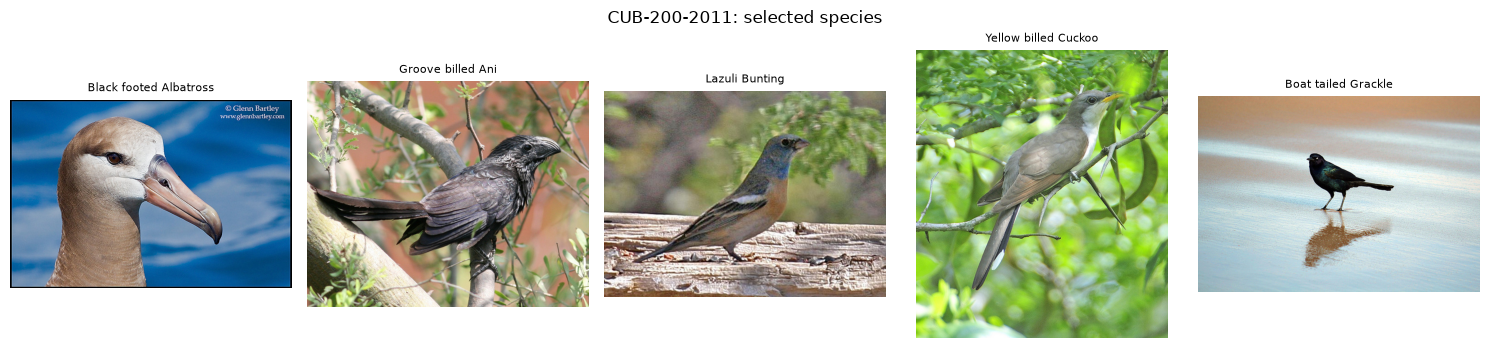

In [2]:
fig, axes = plt.subplots(1, len(class_ids), figsize=(15, 3.5))
for ax, species_id, species_name in zip(axes, class_ids, class_labels):
    sample_path = sorted((SUBSET / str(species_id)).glob("*.jpg"))[0]
    ax.imshow(plt.imread(sample_path))
    ax.set_title(species_name.split(".", 1)[1].replace("_", " "), fontsize=8)
    ax.axis("off")
fig.suptitle("CUB-200-2011: selected species")
fig.tight_layout()
fig.savefig(FIGURES / "exp09_bird_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Build and train the CNN

In [3]:
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(image_paths, image_labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, image_labels))
    if training:
        dataset = dataset.shuffle(len(image_paths), seed=SEED, reshuffle_each_iteration=True)
    return dataset.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False
inputs = tf.keras.layers.Input(shape=(*IMAGE_SIZE, 3))
x = tf.keras.layers.RandomFlip("horizontal", seed=SEED)(inputs)
x = tf.keras.layers.RandomRotation(0.05, seed=SEED)(x)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30, seed=SEED)(x)
outputs = tf.keras.layers.Dense(len(class_ids), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
        )
    ],
    verbose=2,
)

base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
        )
    ],
    verbose=2,
)

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  32768/9406464 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step

  65536/9406464 ━━━━━━━━━━━━━━━━━━━━ 16s 2us/step

 131072/9406464 ━━━━━━━━━━━━━━━━━━━━ 11s 1us/step

 245760/9406464 ━━━━━━━━━━━━━━━━━━━━ 8s 1us/step 

...

11/11 - 4s - 367ms/step - accuracy: 0.9091 - loss: 0.3415 - val_accuracy: 0.9091 - val_loss: 0.1642


Epoch 5/6


11/11 - 4s - 368ms/step - accuracy: 0.9091 - loss: 0.2942 - val_accuracy: 0.9091 - val_loss: 0.1611


Epoch 6/6


11/11 - 4s - 357ms/step - accuracy: 0.9261 - loss: 0.2299 - val_accuracy: 0.9091 - val_loss: 0.1589


## 4. Evaluate and save observations

Test loss: 0.1312
Test accuracy: 0.9818
                            precision    recall  f1-score   support

001.Black_footed_Albatross       1.00      1.00      1.00        11
     004.Groove_billed_Ani       0.92      1.00      0.96        11
        015.Lazuli_Bunting       1.00      1.00      1.00        11
  033.Yellow_billed_Cuckoo       1.00      1.00      1.00        11
   049.Boat_tailed_Grackle       1.00      0.91      0.95        11

                  accuracy                           0.98        55
                 macro avg       0.98      0.98      0.98        55
              weighted avg       0.98      0.98      0.98        55



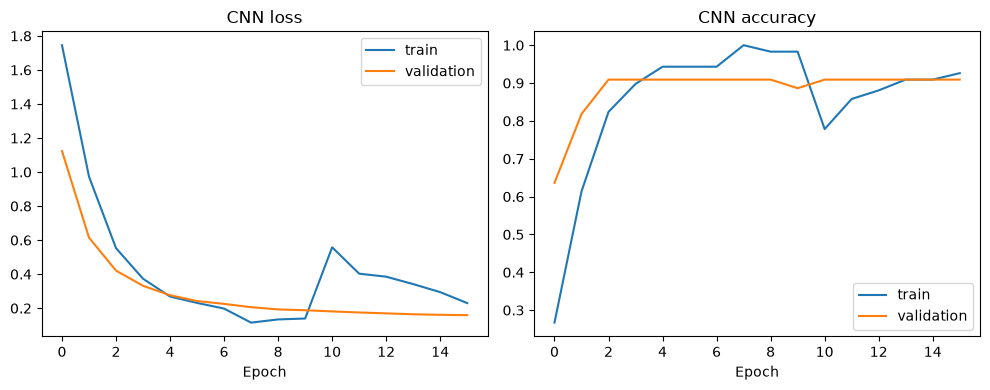

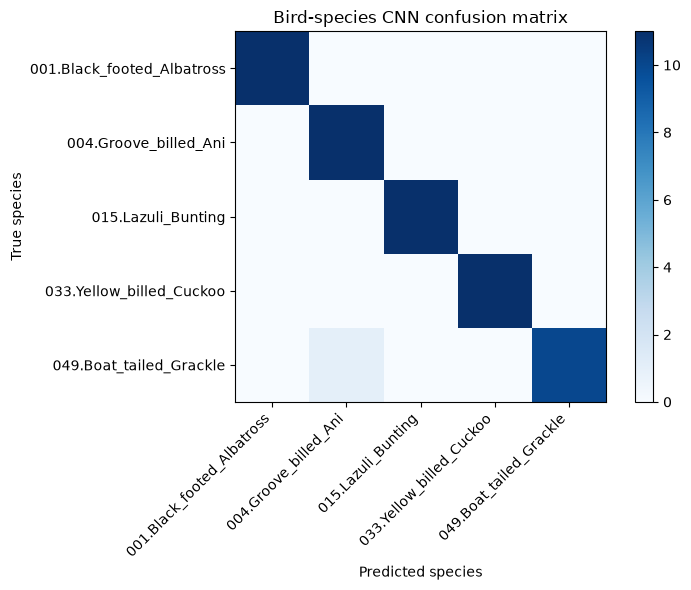

,species_count,train_images,validation_images,test_images,epochs,test_loss,test_accuracy,tensorflow_version
0,5,176,44,55,10,0.131173,0.981818,2.21.0


Observation: this small, fixed CUB subset is an educational run; its measured accuracy should not be generalized to all bird species.


In [4]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
y_true = np.asarray(test_labels)
from sklearn.metrics import classification_report, confusion_matrix

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_labels,
    zero_division=0,
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(report_text)

history_frame = pd.DataFrame(
    {
        key: history.history[key] + fine_tune_history.history[key]
        for key in history.history
    }
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history_frame["loss"], label="train")
axes[0].plot(history_frame["val_loss"], label="validation")
axes[0].set_title("CNN loss")
axes[1].plot(history_frame["accuracy"], label="train")
axes[1].plot(history_frame["val_accuracy"], label="validation")
axes[1].set_title("CNN accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp09_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_ids)))
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_labels)), labels=class_labels, rotation=45, ha="right")
ax.set_yticks(range(len(class_labels)), labels=class_labels)
ax.set_xlabel("Predicted species")
ax.set_ylabel("True species")
ax.set_title("Bird-species CNN confusion matrix")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "exp09_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

metrics = pd.DataFrame(
    [
        {
            "species_count": len(class_ids),
            "train_images": len(train_paths),
            "validation_images": len(val_paths),
            "test_images": len(test_paths),
            "epochs": len(history.history["loss"]),
            "test_loss": float(test_loss),
            "test_accuracy": float(test_accuracy),
            "tensorflow_version": tf.__version__,
        }
    ]
)
metrics.to_csv(RESULTS / "exp09_bird_metrics.csv", index=False)
display(metrics)
print(
    "Observation: this small, fixed CUB subset is an educational run; "
    "its measured accuracy should not be generalized to all bird species."
)

## Observation
The preceding cells print the species, split sizes, per-class precision/recall/F1, confusion matrix, training curves, and held-out test metrics from this run. The subset is small and the split is image-level; images of the same individual may occur across splits.

## Result
Use the printed held-out accuracy and class-wise report as the result for this execution. Discuss confused species and dataset/split limitations; do not compare this score with results from a different dataset or run.